Define flow and capacity for the test case graph

Use the following code block for creating the graph for R1 of Part B.

In [ ]:
import networkx as nx

In [ ]:
G = nx.DiGraph()   #unlike in Project 1, the edges in the network are directed.
G.add_edges_from([(0, 1, {'flow': 2}), (0, 1,{'capacity': 6}),
 (0, 2,{'flow': 3}), (0, 2,{'capacity': 3}),
  (0,3,{'flow': 4}), (0,3,{'capacity': 5}),
   (1,2, {'flow': 1}), (1,2,{'capacity': 5}),
    (1,5, {'flow': 1}), (1,5,{'capacity': 3}),              # modified from last version: edge (1,4) replaced by edge (1,5)
     (2,4, {'flow': 2}), (2,4,{'capacity': 9}),
      (2,5, {'flow': 4}), (2,5,{'capacity': 8}),
       (3,2, {'flow': 2}), (3,2,{'capacity': 2}),
        (3,4,{'flow': 2}), (3,4,{'capacity': 3}),
         (4,5, {'flow': 4}), (4,5,{'capacity': 5})])

In [ ]:
print(G.nodes())
print(G.edges(data=True))

[0, 1, 2, 3, 5, 4]
[(0, 1, {'flow': 2, 'capacity': 6}), (0, 2, {'flow': 3, 'capacity': 3}), (0, 3, {'flow': 4, 'capacity': 5}), (1, 2, {'flow': 1, 'capacity': 5}), (1, 5, {'flow': 1, 'capacity': 3}), (2, 4, {'flow': 2, 'capacity': 9}), (2, 5, {'flow': 4, 'capacity': 8}), (3, 2, {'flow': 2, 'capacity': 2}), (3, 4, {'flow': 2, 'capacity': 3}), (4, 5, {'flow': 4, 'capacity': 5})]


In [ ]:
def HEURISTIC(N, p):
    Δh = float('inf')

    for edges in p:
        residual = N[edges[0]][edges[1]]['capacity'] - N[edges[0]][edges[1]]['flow']
        Δh = min(Δh, residual)

    if Δh <= 0:
        return 0

    return Δh

In [ ]:
p = [(0, 1), (1, 5)]
print(HEURISTIC(G, p))

2


In [ ]:
from itertools import islice

def SUCCESSOR(N, S, T):
    CHILDREN = []

    R = nx.DiGraph()
    R.add_nodes_from(N.nodes())

    for edges in N.edges():
        if N[edges[0]][edges[1]]['capacity'] > N[edges[0]][edges[1]]['flow']:
            R.add_edge(edges[0], edges[1])

    P = islice(nx.all_simple_edge_paths(R, S, T), 100)

    for p in P:
        Δh = HEURISTIC(N, p)

        if Δh > 0:
            childN = N.copy()

            for edges in p:
                childN[edges[0]][edges[1]]['flow'] += Δh

            CHILDREN.append((childN, p, Δh))

    return CHILDREN

In [ ]:
CHILDREN = SUCCESSOR(G, 0, 5)

print("Number of children:", len(CHILDREN))

for childN, p, Δh in CHILDREN:
    print("Path:", p, "Heuristic:", Δh)

Number of children: 4
Path: [(0, 1), (1, 2), (2, 4), (4, 5)] Heuristic: 1
Path: [(0, 1), (1, 2), (2, 5)] Heuristic: 4
Path: [(0, 1), (1, 5)] Heuristic: 2
Path: [(0, 3), (3, 4), (4, 5)] Heuristic: 1


In [ ]:
def HILL_CLIMBING(N, S, T):
    PRESENT = N.copy()

    while True:
        CHILDREN = SUCCESSOR(PRESENT, S, T)

        if not CHILDREN:
            break

        BESTPATH = max(CHILDREN, key=lambda child: child[2])

        if BESTPATH[2] <= 0:
            break

        PRESENT = BESTPATH[0]

    total = sum(PRESENT[edges[0]][edges[1]]['flow']
                for edges in PRESENT.in_edges(T))

    return PRESENT, total

In [ ]:
def INITIAL_FLOW(N, S, T):
    for edges in N.edges():
        N[edges[0]][edges[1]]['flow'] = 0

    for i in range(3):
        R = nx.DiGraph()
        R.add_nodes_from(N.nodes())

        for edges in N.edges():
            if N[edges[0]][edges[1]]['flow'] < N[edges[0]][edges[1]]['capacity']:
                R.add_edge(edges[0], edges[1],
                           weight=random.randint(1, 10))

        if not nx.has_path(R, S, T):
            break

        p = nx.shortest_path(R, S, T, weight='weight')

        Δh = min(N[p[j]][p[j+1]]['capacity'] -
                 N[p[j]][p[j+1]]['flow']
                 for j in range(len(p)-1))

        Δh = random.randint(1, Δh)

        for j in range(len(p)-1):
            N[p[j]][p[j+1]]['flow'] += Δh

    return N

In [ ]:
PRESENT, total = HILL_CLIMBING(G, 0, 5)

print("Total flow into T:", total)

Total flow into T: 14


In [ ]:
import random

N = nx.gnp_random_graph(30, 0.1, seed=42, directed=True)

for edges in N.edges():
    N[edges[0]][edges[1]]['capacity'] = random.randint(1, 10)
    N[edges[0]][edges[1]]['flow'] = 0

S = 0
T = 29

print("Number of nodes:", N.number_of_nodes())
print("Number of edges:", N.number_of_edges())

Number of nodes: 30
Number of edges: 80


In [ ]:
N = INITIAL_FLOW(N, S, T)

PRESENT, tf = HILL_CLIMBING(N, S, T)

tf_net, flow_values = nx.maximum_flow(
    N, S, T, flow_func=nx.algorithms.flow.edmonds_karp
)

print("Hill Climbing flow:", tf)
print("Edmonds-Karp flow:", tf_net)

Hill Climbing flow: 8
Edmonds-Karp flow: 8


In [ ]:
valid = True

for node in PRESENT.nodes():
    if node != S and node != T:
        inflow = sum(PRESENT[u][node]['flow']
                     for u in PRESENT.predecessors(node))

        outflow = sum(PRESENT[node][v]['flow']
                      for v in PRESENT.successors(node))

        if inflow != outflow:
            valid = False
            print("Conservation failed at node:", node)

for edges in PRESENT.edges():
    if not 0 <= PRESENT[edges[0]][edges[1]]['flow'] <= PRESENT[edges[0]][edges[1]]['capacity']:
        valid = False
        print("Capacity violation:", edges)

print("Flow constraints satisfied:", valid)

Flow constraints satisfied: True


In [ ]:
total = 0

for i in range(30):
    N = nx.gnp_random_graph(30, 0.1, directed=True)

    for edges in N.edges():
        N[edges[0]][edges[1]]['capacity'] = random.randint(1, 10)
        N[edges[0]][edges[1]]['flow'] = 0

    N = INITIAL_FLOW(N,0,29)
    PRESENT, tf = HILL_CLIMBING(N, 0, 29)
    total += tf

    print("Graph", i + 1, "Flow:", tf)

tf_net_avg_3 = total / 30

print("Average flow:", tf_net_avg_3)

Graph 1 Flow: 9
Graph 2 Flow: 7
Graph 3 Flow: 0
Graph 4 Flow: 0
Graph 5 Flow: 5
Graph 6 Flow: 5
Graph 7 Flow: 7
Graph 8 Flow: 8
Graph 9 Flow: 11
Graph 10 Flow: 10
Graph 11 Flow: 0
Graph 12 Flow: 7
Graph 13 Flow: 17
Graph 14 Flow: 2
Graph 15 Flow: 0
Graph 16 Flow: 8
Graph 17 Flow: 6
Graph 18 Flow: 0
Graph 19 Flow: 0
Graph 20 Flow: 10
Graph 21 Flow: 2
Graph 22 Flow: 11
Graph 23 Flow: 8
Graph 24 Flow: 6
Graph 25 Flow: 0
Graph 26 Flow: 0
Graph 27 Flow: 3
Graph 28 Flow: 10
Graph 29 Flow: 7
Graph 30 Flow: 5
Average flow: 5.466666666666667


In [ ]:
total = 0

for i in range(30):
    N = nx.gnp_random_graph(30, 2/30, directed=True)

    for edges in N.edges():
        N[edges[0]][edges[1]]['capacity'] = random.randint(1, 10)
        N[edges[0]][edges[1]]['flow'] = 0

    N= INITIAL_FLOW(N, 0, 29)
    PRESENT, tf = HILL_CLIMBING(N, 0, 29)
    total += tf

    print("Graph", i + 1, "Flow:", tf)

tf_net_avg_2 = total / 30

print("Average flow (connectivity 2):", tf_net_avg_2)

Graph 1 Flow: 2
Graph 2 Flow: 0
Graph 3 Flow: 3
Graph 4 Flow: 2
Graph 5 Flow: 6
Graph 6 Flow: 17
Graph 7 Flow: 8
Graph 8 Flow: 4
Graph 9 Flow: 2
Graph 10 Flow: 0
Graph 11 Flow: 1
Graph 12 Flow: 8
Graph 13 Flow: 0
Graph 14 Flow: 0
Graph 15 Flow: 6
Graph 16 Flow: 0
Graph 17 Flow: 0
Graph 18 Flow: 1
Graph 19 Flow: 0
Graph 20 Flow: 0
Graph 21 Flow: 2
Graph 22 Flow: 3
Graph 23 Flow: 1
Graph 24 Flow: 0
Graph 25 Flow: 0
Graph 26 Flow: 11
Graph 27 Flow: 7
Graph 28 Flow: 4
Graph 29 Flow: 0
Graph 30 Flow: 2
Average flow (connectivity 2): 3.0


### R3(c): Comparison of Average Flow

The average total flow for connectivity 3 was 5.47, while the average total flow for connectivity 2 was 3.00. The difference is 2.47, showing that higher connectivity produced a larger average flow in these experiments.

This occurs because networks with more connections generally provide more possible paths from source S to sink T. When one path reaches its maximum capacity, the algorithm may find alternative paths to increase the total flow. Networks with lower connectivity have fewer alternative paths and may experience more bottlenecks or missing connections. Therefore, higher connectivity generally allows more flow to reach the sink.

**Implementation Note:** The Hill Climbing algorithm considers up to 100 candidate paths per iteration to limit memory usage. Initial flows are randomly generated along source-to-sink paths to maintain flow conservation. Some edges may have zero initial flow because assigning positive flows independently to every edge does not necessarily satisfy conservation.

Obtain all paths from a *source* node to a *target* node. This is done by a depth first search. In case, the number of paths searched is excessive we can cut off the search at depth given by *cutoff*, this is essentially a depth limited search.

In [ ]:
for path in nx.all_simple_edge_paths(G, source=0, target=5, cutoff=9):
  print(path)

[(0, 1), (1, 2), (2, 4), (4, 5)]
[(0, 1), (1, 2), (2, 5)]
[(0, 1), (1, 5)]
[(0, 2), (2, 4), (4, 5)]
[(0, 2), (2, 5)]
[(0, 3), (3, 2), (2, 4), (4, 5)]
[(0, 3), (3, 2), (2, 5)]
[(0, 3), (3, 4), (4, 5)]


{(0, 1): 2, (0, 2): 3, (0, 3): 4, (1, 2): 1, (1, 5): 1, (2, 4): 2, (2, 5): 4, (3, 2): 2, (3, 4): 2, (4, 5): 4}


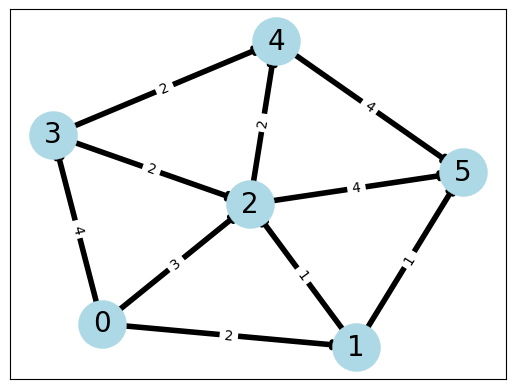

In [ ]:
import matplotlib.pyplot as plt

links = [(u, v) for (u, v, d) in G.edges(data=True)]
pos = nx.nx_pydot.graphviz_layout(G)
nx.draw_networkx_nodes(G, pos, node_size=1200, node_color='lightblue', linewidths=0.25) # draw nodes
nx.draw_networkx_edges(G, pos, edgelist=links, width=4)                                 # draw edges

# node labels
nx.draw_networkx_labels(G, pos, font_size=20, font_family="sans-serif")
# edge weight labels
edge_labels = nx.get_edge_attributes(G, 'flow')
print(edge_labels)
nx.draw_networkx_edge_labels(G, pos, edge_labels)

plt.show()

In [ ]:
from networkx.algorithms.flow import edmonds_karp
R = edmonds_karp(G, 0, 5)
flow_value = nx.maximum_flow_value(R, 0, 5) # The Edmonds Karp algorithm computes out the optimal flow for any given graph. Note that node 4 represents the sink node T.
print(flow_value)

14


In [ ]:
import random
import math